In [ ]:
import spacetrack.operators as op
from spacetrack import SpaceTrackClient
import datetime as dt
import re
import json
import numpy as np
from skyfield.api import load
from functions.functions import compute_reflection
from mpl_toolkits.basemap import Basemap
import matplotlib.pyplot as plt
import pymap3d
import os
from dotenv import load_dotenv



##################################################################
############################# INPUTS #############################
##################################################################

#CYGNSS ID, Start time, End time
#cyg01,2018-08-22 14:26:59,2018-08-22 14:27:59

#PRN Code
#20
#14 -> the satellite that had PRN 14 in 2018 is not active nowadays
#10
#32
# CYGNSS ID name
sat_name = "cygfm01"  # Change this to the satellite name you want
##################################################################

# Retrieve access to TLEs to SpaceTrack
dotenv_path = os.path.join(os.path.dirname(os.getcwd()), '.env')
load_dotenv(dotenv_path)
identity = os.getenv("SPACETRACK_ID")
pw = os.getenv("SPACETRACK_PASS")
# Let's keep it private it....
st = SpaceTrackClient(identity=identity, password=pw)

# Define the PRN codes and the time range
PNR_vec = [20, 10, 32]
date_start = dt.datetime(2018, 8, 22, 14, 26, 59)
date_end = dt.datetime(2018, 8, 22, 14, 27, 59)


# Read the GPS (updated) TLE file to relate PRN to NORAD ID
# To be updated when we have all PRN values for non active GPS satellites 
input_file = "../TLE_EPHEMIRIS_files/GPS_operational.tle"# Extract PRN Code and NORAD ID
with open(input_file, "r") as file:
    tle_data = file.read()

pattern = re.compile(r"GPS .+\(PRN (\d+)\)\s+1 (\d+)U")
matches = pattern.findall(tle_data)

# One day search for the TLEs on spacetrack
date_1 = date_start.date()
date_2 = date_start.date() + dt.timedelta(days=1)
# Set range for search of TLEs
drange = op.inclusive_range(date_1, date_2)

##################################################################
########## Create GPS TLE file for all satellites (PRN) ##########
##################################################################
# Empty the file before writing new data
with open("../TLE_EPHEMIRIS_files/ALL_GPS_TLE.txt", "w") as file:
    file.write("")  # Clears the file

# Now open in append mode to add new data
with open("../TLE_EPHEMIRIS_files/ALL_GPS_TLE.txt", "a") as file:
    for PNR in PNR_vec: 

        match = next((m for m in matches if int(m[0]) == PNR), None)     

        if match:
                
            # NORAD ID
            norad_cat_id = match[1]

            #lines = list(st.tle_publish(iter_lines=True, norad_cat_id=norad_cat_id, publish_epoch=drange, orderby='PUBLISH_EPOCH', format='tle'))
            lines = list(st.tle(iter_lines=True, norad_cat_id=norad_cat_id, epoch=drange, orderby="EPOCH", format="tle"))
            # Access the last two elements (most recent time-wise)
            if lines:
                last_elements = lines[-2:]
                print(last_elements)

                # Write the NORAD ID as a header and the TLE data to the file (no extra spaces)
                file.write(f"NORAD ID: {norad_cat_id}\n")  # Header without extra newlines
                for line in last_elements:
                    file.write(line.strip() + "\n")  # Strip leading/trailing spaces and ensure new lines
            else:
                print(f"No data found for PRN {PNR}.")



##################################################################
#################### Create CYGNSS TLE file ######################
##################################################################
sat_data = st.satcat(satname=sat_name, format='json')
# Empty the file before writing new data
with open("../TLE_EPHEMIRIS_files/cygnss_TLE.txt", "w") as file:
    file.write("")  # Clears the file

# Print the results
if sat_data:
    # Parse JSON
    satellite_data = json.loads(sat_data)
    norad_cat_id_cy = satellite_data[0].get("NORAD_CAT_ID")
    lines = list(st.tle(iter_lines=True, norad_cat_id=norad_cat_id_cy, epoch=drange, orderby="EPOCH", format="tle"))
    # Access the last two elements (most recent time-wise)
    if lines:
        last_elements = lines[-2:]
        print(last_elements)
    # Now open in append mode to add new data
    with open("../TLE_EPHEMIRIS_files/cygnss_TLE.txt", "a") as file:

            # Write the NORAD ID as a header and the TLE data to the file (no extra spaces)
            file.write(f"NORAD ID: {norad_cat_id_cy}\n")  # Header without extra newlines
            for line in last_elements:
                file.write(line.strip() + "\n")  # Strip leading/trailing spaces and ensure new lines

else:
    print("Satellite not found.")


['1 26360U 00025A   18234.74896528 -.00000052 +00000-0 +00000-0 0  9999', '2 26360 053.2195 136.8907 0039654 120.7902 149.7268 02.00563248133998']
['1 41019U 15062A   18234.91080196 -.00000049  00000-0  00000+0 0  9994', '2 41019  55.0899 143.1293 0038013 203.7564 156.0918  2.00564521 20566']
['1 41328U 16007A   18234.99893691  .00000010  00000-0  00000+0 0  9994', '2 41328  54.8358 202.8338 0024422 219.4670 140.3284  2.00560666 18622']
['1 41887U 16078D   18234.39436576  .00000266  00000-0  16005-4 0  9991', '2 41887  34.9523 229.8814 0016957 231.1427 128.7771 15.13997538 93228']


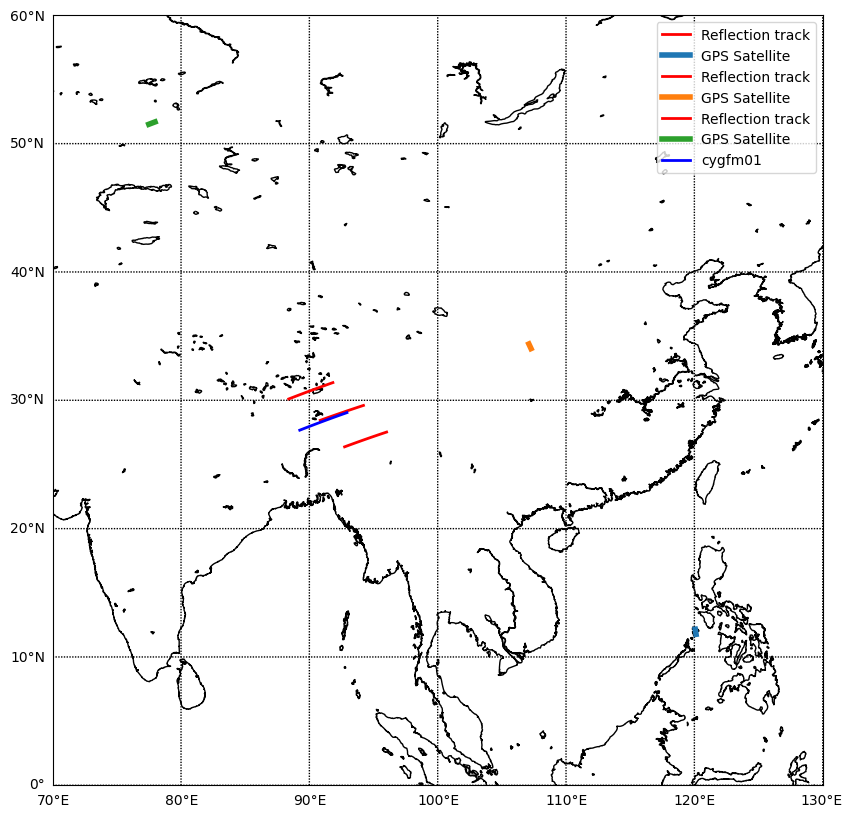

In [ ]:
# Load the TLE file and create the satellites objects
gps_tle_file_path = "../TLE_EPHEMIRIS_files/ALL_GPS_TLE.txt"
sat_tle_file_path = "../TLE_EPHEMIRIS_files/cygnss_TLE.txt"
satellites_LEO_sk = load.tle_file(sat_tle_file_path)
satellites_GPS_sk = load.tle_file(gps_tle_file_path)


# Plot with basemap for good visualization of Earth surface
plt.figure(figsize=(10, 10))
m = Basemap(projection='cyl',llcrnrlat=0,urcrnrlat=60,
            llcrnrlon=70,urcrnrlon=130, resolution='i')

m.drawcoastlines()
# Define latitude and longitude intervals suitable for zoomed-in view -> only for this case. Make it general
parallels = range(0, 61, 10)   # Latitude lines every 10 degrees
meridians = range(70, 131, 10)  # Longitude lines every 10 degrees

# Draw latitude and longitude grid lines with labels
m.drawparallels(parallels, labels=[1, 0, 0, 0], fontsize=10)  # Latitude labels on the left
m.drawmeridians(meridians, labels=[0, 0, 0, 1], fontsize=10)  # Longitude labels on the bottom

# Generate Seconds time vector to add it to the time object. 
step = 1 # Seconds between each point
seconds_array = np.arange(0, (date_end - date_start).total_seconds(), step)
# Load timescale and generate Skyfield time series
start_time_dt = date_start 
ts = load.timescale()
times_1 = ts.utc(
    start_time_dt.year,
    start_time_dt.month,
    start_time_dt.day,
    start_time_dt.hour,
    start_time_dt.minute,
    start_time_dt.second + seconds_array
)

# Need to create another datime obect, times_2, to run the latitude, longitude conversion
times_2 = [time.utc_datetime() for time in times_1]  # Call the method on each Time object


satellite_leo = satellites_LEO_sk[0]
position2 = np.array([satellite_leo.at(t).position.m       for t in times_1])
#velocity2 = np.array([satellite_leo.at(t).velocity.m_per_s for t in times_1])
position2 = np.transpose(position2)


# Iterate along different GPS satellites (and PRN codes)
for satellite_gps in satellites_GPS_sk:
    # Extract position and velocity vectors
    position1 = np.array([satellite_gps.at(t).position.m       for t in times_1])
    #velocity1 = np.array([satellite_gps.at(t).velocity.m_per_s for t in times_1])
    position1 = np.transpose(position1)
    specular_point_vec, theta_vec, latlon_ref = compute_reflection(position1, position2, 0, 45, times_2)
    # Access fits columns
    # access first column
    m.plot(latlon_ref[:, 1], latlon_ref[:, 0], linewidth=2, color='r', label = "Reflection track")


    lat, lon, alt = pymap3d.eci2geodetic(position1[0, :], position1[1, :], position1[2, :], times_2)
    m.plot(lon, lat, linewidth=4, label = "GPS Satellite")

lat, lon, alt = pymap3d.eci2geodetic(position2[0, :], position2[1, :], position2[2, :], times_2)
m.plot(lon, lat, linewidth=2, color='b', label = sat_name)
# add ticks on x, y axis
plt.xticks(fontsize=12)
plt.legend()
plt.show()
